# Book Recommender on a Medallion Data Lake

**Aman Sharma · MSD25024** · Data Mining Lab Assignment

Raw CSVs → **Bronze** (untouched copy) → **Silver** (cleaned) → **Gold** (model-ready) → item-based collaborative filtering recommender.

In [1]:
import html, io, os, urllib.request, zipfile
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 80)
for folder in ["bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

## Step 1: Bronze layer
Download the zip, then load each file **as is**: `;` separator, `latin-1` encoding, every column read as text.
`escapechar` is needed only for books, because some titles contain `\"`.

In [2]:
URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
if not os.path.exists("raw"):
    request = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})   # the CDN returns 403 without it
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(request).read())).extractall("raw")

now = pd.Timestamp.now()
for table, file, extra in [("users", "BX-Users.csv", {}),
                           ("books", "BX-Books.csv", {"escapechar": "\\"}),
                           ("ratings", "BX-Book-Ratings.csv", {})]:
    df = pd.read_csv(f"raw/{file}", sep=";", encoding="latin-1", dtype=str, **extra)
    df["ingestion_timestamp"] = now
    df.to_parquet(f"bronze/{table}.parquet", index=False)
    print(f"{table:8} {df.shape}")

users    (278858, 4)


books    (271379, 9)


ratings  (1149780, 4)


## Step 2: EDA on Bronze

In [3]:
users, books, ratings = (pd.read_parquet(f"bronze/{t}.parquet") for t in ["users", "books", "ratings"])

for name, df in [("USERS", users), ("BOOKS", books), ("RATINGS", ratings)]:
    print(name, df.shape)
    print(pd.DataFrame({"dtype": df.dtypes, "missing": df.isna().sum()}), "\n")

USERS (278858, 4)
                              dtype  missing
User-ID                      object        0
Location                     object        0
Age                          object   110762
ingestion_timestamp  datetime64[us]        0 

BOOKS (271379, 9)
                              dtype  missing
ISBN                         object        0
Book-Title                   object        0
Book-Author                  object        2
Year-Of-Publication          object        0
Publisher                    object        2
Image-URL-S                  object        0
Image-URL-M                  object        0
Image-URL-L                  object        0
ingestion_timestamp  datetime64[us]        0 

RATINGS (1149780, 4)
                              dtype  missing
User-ID                      object        0
ISBN                         object        0
Book-Rating                  object        0
ingestion_timestamp  datetime64[us]        0 



**Found:** Users 278,858 × 3, Books 271,379 × 8, Ratings 1,149,780 × 3; every column is text in Bronze. Age is missing for 110,762 users (40%); 2 authors and 2 publishers are missing.
**Silver:** cast ids, ratings, age and year to numbers; fill missing ages with the median.

In [4]:
rating = ratings["Book-Rating"].astype(int)
print(rating.value_counts().sort_index().to_string())
print(f"\nRating 0: {(rating == 0).sum():,} ({(rating == 0).mean():.0%})")

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610



Rating 0: 716,109 (62%)


**Found:** 716,109 of 1,149,780 ratings (62%) are 0, meaning "no explicit rating"; real ratings lean high (8 is the most common).
**Silver:** drop the 0s and keep 1–10.

Age:  min 0, max 244, under 5: 882, over 100: 366
Year: year 0: 4619, future: 11 (max 2050)


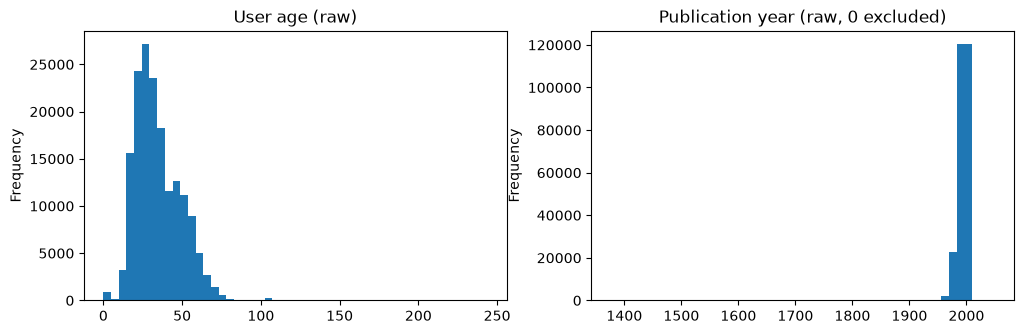

In [5]:
age = pd.to_numeric(users["Age"])
year = pd.to_numeric(books["Year-Of-Publication"])
print(f"Age:  min {age.min():.0f}, max {age.max():.0f}, under 5: {(age < 5).sum()}, over 100: {(age > 100).sum()}")
print(f"Year: year 0: {(year == 0).sum()}, future: {(year > datetime.now().year).sum()} (max {year.max()})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
age.plot.hist(bins=50, ax=ax[0], title="User age (raw)")
year[year > 0].plot.hist(bins=50, ax=ax[1], title="Publication year (raw, 0 excluded)")
plt.show()

**Found:** ages run from 0 to 244 (882 users under 5, 366 over 100); 4,619 books have year 0 and 11 have a future year (up to 2050).
**Silver:** ages outside 5–100 → null → median; year 0 or future → null.

In [6]:
per_user = ratings["User-ID"].value_counts()
per_book = ratings["ISBN"].value_counts()
for name, s in [("user", per_user), ("book", per_book)]:
    print(f"Ratings per {name}: median {s.median():.0f}, mean {s.mean():.1f}, max {s.max()}, "
          f"share with only 1: {(s == 1).mean():.0%}, share with 10+: {(s >= 10).mean():.1%}")

Ratings per user: median 1, mean 10.9, max 13602, share with only 1: 56%, share with 10+: 12.4%
Ratings per book: median 1, mean 3.4, max 2502, share with only 1: 58%, share with 10+: 5.4%


**Found:** the median user and the median book both have just 1 rating; only 12.4% of users and 5.4% of books have 10 or more.
**Silver:** keep only users and books with a minimum number of ratings (threshold chosen below).

In [7]:
filled = len(ratings) / (len(per_user) * len(per_book))
print(f"{len(per_user):,} users x {len(per_book):,} books -> {filled:.4%} of pairs have a rating")

105,283 users x 340,556 books -> 0.0032% of pairs have a rating


**Found:** 105,283 users × 340,556 books with only 0.0032% of pairs rated.
**Silver/Gold:** store the matrix as sparse; the rating threshold will make it far denser.

## Step 3: Silver layer (cleaning)

In [8]:
def clean_text(s):
    """Decode '&amp;', squeeze spaces, Title Case (keeping "Potter's"), and turn blanks into nulls."""
    s = s.map(html.unescape, na_action="ignore").str.replace(r"\s+", " ", regex=True).str.strip()
    s = s.str.title().str.replace(r"'(\w)", lambda m: "'" + m[1].lower(), regex=True)
    return s.replace({"": np.nan, "N/A": np.nan})

def load_bronze(table, columns):
    return pd.read_parquet(f"bronze/{table}.parquet").drop(columns="ingestion_timestamp").rename(columns=columns)

users = load_bronze("users", {"User-ID": "user_id", "Location": "location", "Age": "age"})
books = load_bronze("books", {"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                              "Year-Of-Publication": "year", "Publisher": "publisher"})
ratings = load_bronze("ratings", {"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

# types + ISBN normalised first, so duplicates and joins match correctly
users = users.astype({"user_id": int}).assign(age=pd.to_numeric(users["age"]))
ratings = ratings.astype({"user_id": int, "rating": int})
books["isbn"], ratings["isbn"] = books["isbn"].str.strip().str.upper(), ratings["isbn"].str.strip().str.upper()

# 1. duplicates
before = len(users), len(books), len(ratings)
users = users.drop_duplicates("user_id")
books = books.drop_duplicates("isbn")
ratings = ratings.drop_duplicates(["user_id", "isbn"])
print("Duplicates removed (users, books, ratings):", tuple(b - len(d) for b, d in zip(before, [users, books, ratings])))

# 2. explicit ratings only
ratings = ratings[ratings["rating"].between(1, 10)]

# 3. impossible ages -> null -> median
users["age"] = users["age"].where(users["age"].between(5, 100))
users["age"] = users["age"].fillna(users["age"].median())

# 4. "city, state, country" -> three columns (state only when there are 3+ parts)
parts = users.pop("location").str.split(",")
users["city"] = parts.str[0]
users["state"] = parts.str[1].where(parts.str.len() >= 3)
users["country"] = parts.str[-1].where(parts.str.len() >= 2)

# 5. year 0 or in the future -> null
books["year"] = pd.to_numeric(books["year"])
books["year"] = books["year"].where(books["year"].between(1, datetime.now().year)).astype("Int64")

# 6. text columns; image URLs are not needed
for col in ["title", "author", "publisher"]:
    books[col] = clean_text(books[col])
for col in ["city", "state", "country"]:
    users[col] = clean_text(users[col])
books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])

# 7. ratings must point to a known user and book
ratings = ratings[ratings["user_id"].isin(users["user_id"]) & ratings["isbn"].isin(books["isbn"])]
print("Explicit ratings with a known user and book:", f"{len(ratings):,}")

Duplicates removed (users, books, ratings): (0, 315, 0)


Explicit ratings with a known user and book: 383,853


In [9]:
# what survives at each threshold (single pass, before the repeated filter)
u, b = ratings["user_id"].value_counts(), ratings["isbn"].value_counts()
pd.DataFrame({"users kept": [(u >= t).sum() for t in [1, 5, 10, 20, 50]],
              "books kept": [(b >= t).sum() for t in [1, 5, 10, 20, 50]]}, index=[1, 5, 10, 20, 50]).rename_axis("min ratings")

,users kept,books kept
min ratings,,
1,68092,149723
5,12787,13790
10,6589,5446
20,3305,2131
50,1180,531


**Chosen threshold: 10 ratings, for both users and books.**
- The EDA shows most users and books have a single rating, which gives no usable cosine similarity.
- At 5 we keep 13,790 books, most with too few shared raters for a stable similarity score.
- At 20 only 2,131 books survive even one pass, which is too small a catalogue.
- 10 leaves 1,820 users × 2,030 books (41,469 ratings, 1.12% filled, about 350× denser than the raw matrix).

In [10]:
MIN_RATINGS = 10

# dropping users can push books under the limit and vice versa, so repeat until stable
while True:
    n = len(ratings)
    ratings = ratings[ratings.groupby("user_id")["rating"].transform("size") >= MIN_RATINGS]
    ratings = ratings[ratings.groupby("isbn")["rating"].transform("size") >= MIN_RATINGS]
    if len(ratings) == n:
        break

users = users[users["user_id"].isin(ratings["user_id"])]
books = books[books["isbn"].isin(ratings["isbn"])]
for table, df in [("users", users), ("books", books), ("ratings", ratings)]:
    df.to_parquet(f"silver/{table}.parquet", index=False)
    print(f"silver/{table:8} {len(df):,} rows")

silver/users    1,820 rows
silver/books    2,030 rows
silver/ratings  41,469 rows


## Step 4: Gold layer
Category codes give every user a row number and every book a column number.
The book lookup is saved **in column order**, so row `i` of the lookup is column `i` of the matrix.

In [11]:
users, books, ratings = (pd.read_parquet(f"silver/{t}.parquet") for t in ["users", "books", "ratings"])

user_cat = ratings["user_id"].astype("category")
book_cat = ratings["isbn"].astype("category")
matrix = sparse.csr_matrix((ratings["rating"], (user_cat.cat.codes, book_cat.cat.codes)))   # users x books

sparse.save_npz("gold/rating_matrix.npz", matrix)
pd.DataFrame({"user_id": user_cat.cat.categories}).to_parquet("gold/matrix_users.parquet", index=False)
books.set_index("isbn").loc[book_cat.cat.categories, ["title", "author"]].reset_index() \
     .to_parquet("gold/book_lookup.parquet", index=False)

for key, name in [("user_id", "user"), ("isbn", "book")]:
    ratings.groupby(key)["rating"].agg(avg_rating="mean", num_ratings="size").reset_index() \
           .to_parquet(f"gold/{name}_stats.parquet", index=False)

print(f"Matrix {matrix.shape}, {matrix.nnz:,} ratings, {matrix.nnz / np.prod(matrix.shape):.2%} filled")
print("Gold:", sorted(os.listdir("gold")))

Matrix (1820, 2030), 41,469 ratings, 1.12% filled
Gold: ['book_lookup.parquet', 'book_stats.parquet', 'matrix_users.parquet', 'rating_matrix.npz', 'user_stats.parquet']


## Step 5: Item-based collaborative filtering
Rows = books, columns = users. Cosine similarity via `NearestNeighbors`.

In [12]:
matrix = sparse.load_npz("gold/rating_matrix.npz")
user_ids = pd.read_parquet("gold/matrix_users.parquet")["user_id"]
lookup = pd.read_parquet("gold/book_lookup.parquet")          # row i = matrix column i
user_row = pd.Series(range(len(user_ids)), index=user_ids)    # user_id -> matrix row

book_user = matrix.T.tocsr()
model = NearestNeighbors(metric="cosine", algorithm="brute").fit(book_user)

# The 10 books most similar to a title (partial, case-insensitive match; most-rated edition wins).
def similar_books(title, n=10):
    hits = lookup.index[lookup["title"].str.contains(title, case=False, regex=False, na=False)]
    if hits.empty:
        raise ValueError(f"No book matches {title!r}")
    row = hits[np.argmax(book_user[hits].getnnz(axis=1))]
    dist, idx = model.kneighbors(book_user[row], n_neighbors=n + 1)
    out = lookup.iloc[idx[0]].assign(similarity=(1 - dist[0]).round(3))
    print("Similar to:", lookup.at[row, "title"])
    return out.drop(index=row, errors="ignore").head(n).reset_index(drop=True)

similar_books(lookup.at[book_user.getnnz(axis=1).argmax(), "title"])    # the most-rated book

Similar to: The Lovely Bones: A Novel


,index,title,author,similarity
0,0446672211,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219
1,0316096199,Lucky : A Memoir,Alice Sebold,0.218
2,0385504209,The Da Vinci Code,Dan Brown,0.178
3,0316601950,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,0743418174,Good In Bed,Jennifer Weiner,0.176
5,0446531332,Nights In Rodanthe,Nicholas Sparks,0.170
6,0688170528,The Pact: A Love Story,Jodi Picoult,0.168
7,0316603287,The Lake House,James Patterson,0.166
8,0684857820,Lucky,Alice Sebold,0.165
9,0316284955,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


`recommend` in one matrix product: keep the user's ratings ≥ 7, multiply by the top-30 similarity graph,
so each candidate scores **Σ similarity × user's rating** over the liked books. Then drop anything already read
(by title, which also catches other editions) and return the top `n`.

In [13]:
LIKED, NEIGHBOURS = 7, 30

similarity = model.kneighbors_graph(n_neighbors=NEIGHBOURS, mode="distance")   # each book's 30 nearest other books
similarity.data = 1 - similarity.data                                          # cosine distance -> similarity

# Books the user rated LIKED or more, best first.
def liked_books(user_id):
    rated = matrix[user_row[user_id]]
    out = lookup.iloc[rated.indices].assign(rating=rated.data)
    return out[out["rating"] >= LIKED].sort_values("rating", ascending=False)

# Top-n unread books, scored by similarity to the user's liked books weighted by their rating.
def recommend(user_id, n=10):
    rated = matrix[user_row[user_id]]
    scores = (rated.multiply(rated >= LIKED) @ similarity).toarray().ravel()
    recs = lookup.assign(score=scores.round(2))
    recs = recs[(recs["score"] > 0) & ~recs["title"].isin(lookup["title"].iloc[rated.indices])]
    return recs.sort_values("score", ascending=False).drop_duplicates("title").head(n).reset_index(drop=True)

## Step 6: Demo and sanity check
Three random users (fixed seed) who liked at least 5 books.

In [14]:
n_liked = np.asarray((matrix >= LIKED).sum(axis=1)).ravel()
demo_users = user_ids[n_liked >= 5].sample(3, random_state=42)

def label(df):
    return (df["title"] + " — " + df["author"].fillna("?")).reset_index(drop=True)

for u in demo_users:
    print(f"\nUser {u}")
    display(pd.DataFrame({"Rated highly": label(liked_books(u).head(10)), "Recommended": label(recommend(u))}).fillna(""))


User 152186


,Rated highly,Recommended
0,Little House On The Prairie — Laura Ingalls Wilder,The Ritual Bath (Peter Decker & Rina Lazarus Novels (Paperback)) — Faye Kell...
1,Not Without My Daughter — Betty Mahmoody,The Gift — Danielle Steel
2,Now You See Me — Tina Wainscott,F Is For Fugitive (Kinsey Millhone Mysteries (Paperback)) — Sue Grafton
3,Full House (Janet Evanovich's Full Series) — Janet Evanovich,B Is For Burglar (Kinsey Millhone Mysteries (Paperback)) — Sue Grafton
4,The Lovely Bones: A Novel — Alice Sebold,"""O"" Is For Outlaw — Sue Grafton"
5,Southern Cross — Patricia Daniels Cornwell,Mixed Blessings — Danielle Steel
6,Hostage — Robert Crais,I Is For Innocent — Sue Grafton
7,Mindhunter : Inside The Fbi's Elite Serial Crime Unit — John E. Douglas,The Clinic (Alex Delaware Novels (Paperback)) — Jonathan Kellerman
8,Pride And Prejudice — Jane Austen,Midnight Voices — John Saul
9,The Dark Room — Minette Walters,E Is For Evidence: A Kinsey Millhone Mystery (Kinsey Millhone Mysteries (Pap...



User 47128


,Rated highly,Recommended
0,The Nanny Diaries: A Novel — Emma Mclaughlin,The Green Mile: The Bad Death Of Eduard Delacroix (Green Mile Series) — Step...
1,Find Me — Rosie O'donnell,The Green Mile: Coffey's Hands (Green Mile Series) — Stephen King
2,The Green Mile: Coffey On The Mile (Green Mile Series) — Stephen King,The Two Dead Girls (Green Mile Series) — Stephen King
3,Needful Things — Stephen King,The Tommyknockers — Stephen King
4,Rose Madder — Stephen King,Nightmares & Dreamscapes — Stephen King
5,The Green Mile: The Mouse On The Mile (Green Mile Series) — Stephen King,"The Bachman Books: Rage, The Long Walk, Roadwork, The Running Man — Stephen ..."
6,Back Roads — Tawni O'dell,Gerald's Game — Stephen King
7,The Green Mile: Night Journey (Green Mile Series) — Stephen King,Stephen King's Danse Macabre — Stephen King
8,Four Blind Mice — James Patterson,It — Stephen King
9,Shadowfires — Dean R. Koontz,Pet Sematary — Stephen King



User 68256


,Rated highly,Recommended
0,Me Talk Pretty One Day — David Sedaris,Harry Potter And The Order Of The Phoenix (Book 5) — J. K. Rowling
1,"The Dilbert Principle: A Cubicle's-Eye View Of Bosses, Meetings, Management ...",Harry Potter And The Sorcerer's Stone (Book 1) — J. K. Rowling
2,Harry Potter And The Prisoner Of Azkaban (Book 3) — J. K. Rowling,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Row...
3,The Sisterhood Of The Traveling Pants — Ann Brashares,A Walk To Remember — Nicholas Sparks
4,Bridget Jones's Diary — Helen Fielding,Charlotte's Web (Trophy Newbery) — E. B. White
5,Where The Heart Is (Oprah's Book Club (Paperback)) — Billie Letts,Fight Club — Chuck Palahniuk
6,Harry Potter And The Goblet Of Fire (Book 4) — J. K. Rowling,To Love Again — Danielle Steel
7,Bridget Jones : The Edge Of Reason — Helen Fielding,Prodigal Summer — Barbara Kingsolver
8,Harry Potter And The Chamber Of Secrets (Book 2) — J. K. Rowling,Naked — David Sedaris
9,,How To Be Good — Nick Hornby


In [15]:
# every demo user gets 10 recommendations, none of them already read
for u in demo_users:
    recs, read = recommend(u), set(lookup["title"].iloc[matrix[user_row[u]].indices])
    assert len(recs) == 10 and not set(recs["title"]) & read, u
print("Sanity checks passed")
print({layer: sorted(os.listdir(layer)) for layer in ["bronze", "silver", "gold"]})

Sanity checks passed
{'bronze': ['books.parquet', 'ratings.parquet', 'users.parquet'], 'silver': ['books.parquet', 'ratings.parquet', 'users.parquet'], 'gold': ['book_lookup.parquet', 'book_stats.parquet', 'matrix_users.parquet', 'rating_matrix.npz', 'user_stats.parquet']}


**Result:** the recommendations follow each user's taste. The Stephen King / Green Mile reader gets the rest of the Green Mile series and more King; the Harry Potter and David Sedaris reader gets the other Potter books and another Sedaris; the crime reader gets Sue Grafton's Kinsey Millhone mysteries and Kellerman thrillers. No recommendation is a book the user already read.